In [7]:
import os

print(os.listdir('/content'))

['.config', '82da1ebe-c0d6-45c4-9785-1e1ab0a9ec3f.csv', 'sample_data']


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

df = pd.read_csv('/content/82da1ebe-c0d6-45c4-9785-1e1ab0a9ec3f.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (26806, 4)


In [9]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Date', 'Rain', 'Temp Max', 'Temp Min']


In [10]:
print("\nFirst 10 rows:")
display(df.head(10))


First 10 rows:


,Date,Rain,Temp Max,Temp Min
0,01-01-1951,0,20.13999939,3.680000067
1,02-01-1951,0,21.68000031,3.599999905
2,03-01-1951,0,21.28000069,3.50999999
3,04-01-1951,0,21.61000061,4.090000153
4,05-01-1951,0,21.38999939,5.099999905
5,06-01-1951,0,20.98999977,6.210000038
6,07-01-1951,0.133744702,20.26000023,7.869999886
7,08-01-1951,0,17.5,6.739999771
8,09-01-1951,0,20.01000023,5.579999924
9,10-01-1951,0,20.09000015,5.920000076


In [11]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26806 entries, 0 to 26805
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      26806 non-null  object
 1   Rain      26806 non-null  object
 2   Temp Max  26806 non-null  object
 3   Temp Min  26805 non-null  object
dtypes: object(4)
memory usage: 837.8+ KB


In [12]:
print("\nMissing values:")
display(df.isnull().sum())


Missing values:


,0
Date,0
Rain,0
Temp Max,0
Temp Min,1


In [13]:
# ============================================
# STEP 2: DATA CLEANING AND VALIDATION
# ============================================

# Make a copy of the original dataset
clean_df = df.copy()

# --------------------------------------------
# 1. Convert Date to datetime
# --------------------------------------------
clean_df['Date'] = pd.to_datetime(
    clean_df['Date'],
    errors='coerce'
)

# --------------------------------------------
# 2. Convert numerical columns to numbers
# --------------------------------------------
clean_df['Rain'] = pd.to_numeric(
    clean_df['Rain'],
    errors='coerce'
)

clean_df['Temp Max'] = pd.to_numeric(
    clean_df['Temp Max'],
    errors='coerce'
)

clean_df['Temp Min'] = pd.to_numeric(
    clean_df['Temp Min'],
    errors='coerce'
)

# --------------------------------------------
# 3. Check conversion results
# --------------------------------------------
print("Data types after conversion:")
print(clean_df.dtypes)

print("\nMissing values after conversion:")
display(clean_df.isnull().sum())

# --------------------------------------------
# 4. Check duplicate rows
# --------------------------------------------
print("\nDuplicate rows:", clean_df.duplicated().sum())

# --------------------------------------------
# 5. Check date range
# --------------------------------------------
print("\nDate range:")
print("Start:", clean_df['Date'].min())
print("End:", clean_df['Date'].max())

# --------------------------------------------
# 6. Check basic statistics
# --------------------------------------------
print("\nBasic statistics:")
display(clean_df[['Rain', 'Temp Max', 'Temp Min']].describe())

# --------------------------------------------
# 7. Check invalid temperature records
# Temp Max should normally be >= Temp Min
# --------------------------------------------
invalid_temp = clean_df[
    clean_df['Temp Max'] < clean_df['Temp Min']
]

print("\nRecords where Temp Max < Temp Min:")
print(len(invalid_temp))

# --------------------------------------------
# 8. Display problematic rows
# --------------------------------------------
if len(invalid_temp) > 0:
    display(invalid_temp.head(20))

# --------------------------------------------
# 9. Display cleaned data
# --------------------------------------------
print("\nCleaned dataset:")
display(clean_df.head(10))

Data types after conversion:
Date        datetime64[ns]
Rain               float64
Temp Max           float64
Temp Min           float64
dtype: object

Missing values after conversion:


,0
Date,16234
Rain,103
Temp Max,55
Temp Min,56



Duplicate rows: 72

Date range:
Start: 1951-01-01 00:00:00
End: 2024-12-06 00:00:00

Basic statistics:


,Rain,Temp Max,Temp Min
count,26703.000000,26751.000000,26750.000000
mean,1.851001,31.702441,18.251863
std,8.686634,6.724121,7.621250
min,0.000000,11.650000,0.900000
25%,0.000000,26.565000,11.220000
50%,0.000000,32.900002,19.670000
75%,0.000000,36.240002,25.180000
max,303.422119,47.459999,34.800000



Records where Temp Max < Temp Min:
0

Cleaned dataset:


,Date,Rain,Temp Max,Temp Min
0,1951-01-01,0.000000,20.139999,3.68
1,1951-02-01,0.000000,21.680000,3.60
2,1951-03-01,0.000000,21.280001,3.51
3,1951-04-01,0.000000,21.610001,4.09
4,1951-05-01,0.000000,21.389999,5.10
5,1951-06-01,0.000000,20.990000,6.21
6,1951-07-01,0.133745,20.260000,7.87
7,1951-08-01,0.000000,17.500000,6.74
8,1951-09-01,0.000000,20.010000,5.58
9,1951-10-01,0.000000,20.090000,5.92


In [14]:
# ============================================
# STEP 3: FEATURE CREATION
# ============================================

# Work with the cleaned dataset
analysis_df = clean_df.copy()

# --------------------------------------------
# 1. Create Year
# --------------------------------------------
analysis_df['Year'] = analysis_df['Date'].dt.year

# --------------------------------------------
# 2. Create Month
# --------------------------------------------
analysis_df['Month'] = analysis_df['Date'].dt.month

# --------------------------------------------
# 3. Create Month Name
# --------------------------------------------
analysis_df['Month_Name'] = analysis_df['Date'].dt.month_name()

# --------------------------------------------
# 4. Create Season
# --------------------------------------------
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

analysis_df['Season'] = analysis_df['Month'].apply(get_season)

# --------------------------------------------
# 5. Calculate Average Temperature
# --------------------------------------------
analysis_df['Average_Temperature'] = (
    analysis_df['Temp Max'] + analysis_df['Temp Min']
) / 2

# --------------------------------------------
# 6. Display the new dataset
# --------------------------------------------
print("New columns created successfully!")

print("\nColumns:")
print(analysis_df.columns.tolist())

print("\nFirst 10 rows:")
display(
    analysis_df[
        [
            'Date',
            'Rain',
            'Temp Max',
            'Temp Min',
            'Average_Temperature',
            'Year',
            'Month',
            'Month_Name',
            'Season'
        ]
    ].head(10)
)

# --------------------------------------------
# 7. Check years available
# --------------------------------------------
print("\nYears available:")
print(
    analysis_df['Year'].min(),
    "to",
    analysis_df['Year'].max()
)

print("\nNumber of years:",
      analysis_df['Year'].nunique())

# --------------------------------------------
# 8. Check seasons
# --------------------------------------------
print("\nSeason distribution:")
display(
    analysis_df['Season'].value_counts()
)

# --------------------------------------------
# 9. Check final missing values
# --------------------------------------------
print("\nMissing values:")
display(analysis_df.isnull().sum())

New columns created successfully!

Columns:
['Date', 'Rain', 'Temp Max', 'Temp Min', 'Year', 'Month', 'Month_Name', 'Season', 'Average_Temperature']

First 10 rows:


,Date,Rain,Temp Max,Temp Min,Average_Temperature,Year,Month,Month_Name,Season
0,1951-01-01,0.000000,20.139999,3.68,11.910,1951.0,1.0,January,Winter
1,1951-02-01,0.000000,21.680000,3.60,12.640,1951.0,2.0,February,Winter
2,1951-03-01,0.000000,21.280001,3.51,12.395,1951.0,3.0,March,Summer
3,1951-04-01,0.000000,21.610001,4.09,12.850,1951.0,4.0,April,Summer
4,1951-05-01,0.000000,21.389999,5.10,13.245,1951.0,5.0,May,Summer
5,1951-06-01,0.000000,20.990000,6.21,13.600,1951.0,6.0,June,Monsoon
6,1951-07-01,0.133745,20.260000,7.87,14.065,1951.0,7.0,July,Monsoon
7,1951-08-01,0.000000,17.500000,6.74,12.120,1951.0,8.0,August,Monsoon
8,1951-09-01,0.000000,20.010000,5.58,12.795,1951.0,9.0,September,Monsoon
9,1951-10-01,0.000000,20.090000,5.92,13.005,1951.0,10.0,October,Post-Monsoon



Years available:
1951.0 to 2024.0

Number of years: 74

Season distribution:


,count
Season,
Post-Monsoon,17996
Monsoon,3524
Summer,2643
Winter,2643



Missing values:


,0
Date,16234
Rain,103
Temp Max,55
Temp Min,56
Year,16234
Month,16234
Month_Name,16234
Season,0
Average_Temperature,56


In [15]:
# ============================================
# STEP 3A: INVESTIGATE DATE PROBLEM
# ============================================

# Show original date values that failed conversion
print("Number of invalid dates:", clean_df['Date'].isna().sum())

print("\nExamples of invalid/missing dates:")
display(df.loc[clean_df['Date'].isna(), ['Date']].head(30))

# --------------------------------------------
# Check original Date column
# --------------------------------------------
print("\nOriginal Date examples:")
display(df['Date'].head(30))

# --------------------------------------------
# Check unique date patterns
# --------------------------------------------
print("\nNumber of unique original date values:")
print(df['Date'].nunique())

# --------------------------------------------
# Check date strings by length
# --------------------------------------------
print("\nDate string length distribution:")
display(
    df['Date'].astype(str).str.len().value_counts().sort_index()
)

# --------------------------------------------
# Check for common special values
# --------------------------------------------
print("\nMost common original Date values:")
display(
    df['Date'].value_counts(dropna=False).head(20)
)

# --------------------------------------------
# Show rows around the first invalid date
# --------------------------------------------
invalid_indices = clean_df.index[clean_df['Date'].isna()]

if len(invalid_indices) > 0:
    first_invalid = invalid_indices[0]

    print("\nRows around first invalid date:")
    display(
        df.iloc[
            max(0, first_invalid - 5):
            min(len(df), first_invalid + 6)
        ]
    )

Number of invalid dates: 16234

Examples of invalid/missing dates:


,Date
12,13-01-1951
13,14-01-1951
14,15-01-1951
15,16-01-1951
16,17-01-1951
17,18-01-1951
18,19-01-1951
19,20-01-1951
20,21-01-1951
21,22-01-1951



Original Date examples:


,Date
0,01-01-1951
1,02-01-1951
2,03-01-1951
3,04-01-1951
4,05-01-1951
5,06-01-1951
6,07-01-1951
7,08-01-1951
8,09-01-1951
9,10-01-1951



Number of unique original date values:
26806

Date string length distribution:


,count
Date,
5,3
10,26803



Most common original Date values:


,count
Date,
45465,1
01-01-1951,1
02-01-1951,1
03-01-1951,1
04-01-1951,1
05-01-1951,1
06-06-2024,1
05-06-2024,1
04-06-2024,1



Rows around first invalid date:


,Date,Rain,Temp Max,Temp Min
7,08-01-1951,0,17.5,6.739999771
8,09-01-1951,0,20.01000023,5.579999924
9,10-01-1951,0,20.09000015,5.920000076
10,11-01-1951,0,21.79999924,6.28000021
11,12-01-1951,1.115749598,21.5,7.28000021
12,13-01-1951,0.250126034,22.19000053,9.340000153
13,14-01-1951,0,19.48999977,7.920000076
14,15-01-1951,0,21.47999954,7.25
15,16-01-1951,2.535931826,20.13999939,9.359999657
16,17-01-1951,1.491418481,17.30999947,5.860000134


In [16]:
# ============================================
# STEP 3B: FIX AND VALIDATE DATE COLUMN
# ============================================

# Reload the original dataset
raw_df = pd.read_csv(
    '/content/82da1ebe-c0d6-45c4-9785-1e1ab0a9ec3f.csv'
)

# Clean column names
raw_df.columns = raw_df.columns.str.strip()

# Display sample date values
print("Sample Date values:")
display(raw_df['Date'].head(20))

# --------------------------------------------
# Try multiple date parsing methods
# --------------------------------------------

# Method 1: normal parsing
date_method_1 = pd.to_datetime(
    raw_df['Date'],
    errors='coerce'
)

# Method 2: day-first parsing
date_method_2 = pd.to_datetime(
    raw_df['Date'],
    errors='coerce',
    dayfirst=True
)

print("\nInvalid dates - normal parsing:",
      date_method_1.isna().sum())

print("Invalid dates - day-first parsing:",
      date_method_2.isna().sum())

# --------------------------------------------
# Select the parsing method that works better
# --------------------------------------------

if date_method_1.isna().sum() <= date_method_2.isna().sum():
    raw_df['Date'] = date_method_1
    print("\nUsing normal date parsing.")
else:
    raw_df['Date'] = date_method_2
    print("\nUsing day-first date parsing.")

# --------------------------------------------
# Convert numerical columns
# --------------------------------------------

raw_df['Rain'] = pd.to_numeric(
    raw_df['Rain'],
    errors='coerce'
)

raw_df['Temp Max'] = pd.to_numeric(
    raw_df['Temp Max'],
    errors='coerce'
)

raw_df['Temp Min'] = pd.to_numeric(
    raw_df['Temp Min'],
    errors='coerce'
)

# --------------------------------------------
# Remove completely invalid dates only
# --------------------------------------------

before = len(raw_df)

raw_df = raw_df.dropna(subset=['Date']).copy()

after = len(raw_df)

print("\nRows before date cleaning:", before)
print("Rows after date cleaning:", after)
print("Rows removed:", before - after)

# --------------------------------------------
# Remove exact duplicate rows
# --------------------------------------------

duplicates = raw_df.duplicated().sum()

print("\nDuplicate rows found:", duplicates)

raw_df = raw_df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(raw_df))

# --------------------------------------------
# Check missing numerical values
# --------------------------------------------

print("\nMissing values:")
display(raw_df.isnull().sum())

# --------------------------------------------
# Final date range
# --------------------------------------------

print("\nFinal date range:")
print("Start:", raw_df['Date'].min())
print("End:", raw_df['Date'].max())

# --------------------------------------------
# Display cleaned data
# --------------------------------------------

print("\nCleaned dataset:")
display(raw_df.head(10))

Sample Date values:


,Date
0,01-01-1951
1,02-01-1951
2,03-01-1951
3,04-01-1951
4,05-01-1951
5,06-01-1951
6,07-01-1951
7,08-01-1951
8,09-01-1951
9,10-01-1951



Invalid dates - normal parsing: 16234
Invalid dates - day-first parsing: 3

Using day-first date parsing.

Rows before date cleaning: 26806
Rows after date cleaning: 26803
Rows removed: 3

Duplicate rows found: 0
Rows after removing duplicates: 26803

Missing values:


,0
Date,0
Rain,103
Temp Max,54
Temp Min,55



Final date range:
Start: 1951-01-01 00:00:00
End: 2024-06-19 00:00:00

Cleaned dataset:


,Date,Rain,Temp Max,Temp Min
0,1951-01-01,0.000000,20.139999,3.68
1,1951-01-02,0.000000,21.680000,3.60
2,1951-01-03,0.000000,21.280001,3.51
3,1951-01-04,0.000000,21.610001,4.09
4,1951-01-05,0.000000,21.389999,5.10
5,1951-01-06,0.000000,20.990000,6.21
6,1951-01-07,0.133745,20.260000,7.87
7,1951-01-08,0.000000,17.500000,6.74
8,1951-01-09,0.000000,20.010000,5.58
9,1951-01-10,0.000000,20.090000,5.92


In [17]:
# ============================================
# STEP 4: HANDLE MISSING VALUES
# ============================================

# Make a copy
analysis_df = raw_df.copy()

# --------------------------------------------
# Sort by date
# --------------------------------------------

analysis_df = analysis_df.sort_values('Date').reset_index(drop=True)

# --------------------------------------------
# Check missing values before treatment
# --------------------------------------------

print("Missing values BEFORE treatment:")
display(analysis_df.isnull().sum())

# --------------------------------------------
# Interpolate missing numerical values
# --------------------------------------------

analysis_df['Rain'] = analysis_df['Rain'].interpolate(
    method='linear'
)

analysis_df['Temp Max'] = analysis_df['Temp Max'].interpolate(
    method='linear'
)

analysis_df['Temp Min'] = analysis_df['Temp Min'].interpolate(
    method='linear'
)

# --------------------------------------------
# Fill any remaining missing values
# --------------------------------------------

analysis_df['Rain'] = analysis_df['Rain'].ffill().bfill()
analysis_df['Temp Max'] = analysis_df['Temp Max'].ffill().bfill()
analysis_df['Temp Min'] = analysis_df['Temp Min'].ffill().bfill()

# --------------------------------------------
# Check missing values after treatment
# --------------------------------------------

print("\nMissing values AFTER treatment:")
display(analysis_df.isnull().sum())

# --------------------------------------------
# Create Year
# --------------------------------------------

analysis_df['Year'] = analysis_df['Date'].dt.year

# --------------------------------------------
# Create Month
# --------------------------------------------

analysis_df['Month'] = analysis_df['Date'].dt.month

# --------------------------------------------
# Create Month Name
# --------------------------------------------

analysis_df['Month_Name'] = analysis_df['Date'].dt.month_name()

# --------------------------------------------
# Create Season
# --------------------------------------------

def get_season(month):

    if month in [12, 1, 2]:
        return 'Winter'

    elif month in [3, 4, 5]:
        return 'Summer'

    elif month in [6, 7, 8, 9]:
        return 'Monsoon'

    else:
        return 'Post-Monsoon'


analysis_df['Season'] = analysis_df['Month'].apply(get_season)

# --------------------------------------------
# Calculate Average Temperature
# --------------------------------------------

analysis_df['Average_Temperature'] = (
    analysis_df['Temp Max'] + analysis_df['Temp Min']
) / 2

# --------------------------------------------
# Final validation
# --------------------------------------------

print("\nFinal dataset shape:")
print(analysis_df.shape)

print("\nFinal columns:")
print(analysis_df.columns.tolist())

print("\nDate range:")
print(
    analysis_df['Date'].min(),
    "to",
    analysis_df['Date'].max()
)

print("\nSeason distribution:")
display(
    analysis_df['Season'].value_counts()
)

print("\nFinal dataset preview:")
display(analysis_df.head(10))

Missing values BEFORE treatment:


,0
Date,0
Rain,103
Temp Max,54
Temp Min,55



Missing values AFTER treatment:


,0
Date,0
Rain,0
Temp Max,0
Temp Min,0



Final dataset shape:
(26803, 9)

Final columns:
['Date', 'Rain', 'Temp Max', 'Temp Min', 'Year', 'Month', 'Month_Name', 'Season', 'Average_Temperature']

Date range:
1951-01-01 00:00:00 to 2024-06-19 00:00:00

Season distribution:


,count
Season,
Monsoon,8925
Summer,6808
Winter,6617
Post-Monsoon,4453



Final dataset preview:


,Date,Rain,Temp Max,Temp Min,Year,Month,Month_Name,Season,Average_Temperature
0,1951-01-01,0.000000,20.139999,3.68,1951,1,January,Winter,11.910
1,1951-01-02,0.000000,21.680000,3.60,1951,1,January,Winter,12.640
2,1951-01-03,0.000000,21.280001,3.51,1951,1,January,Winter,12.395
3,1951-01-04,0.000000,21.610001,4.09,1951,1,January,Winter,12.850
4,1951-01-05,0.000000,21.389999,5.10,1951,1,January,Winter,13.245
5,1951-01-06,0.000000,20.990000,6.21,1951,1,January,Winter,13.600
6,1951-01-07,0.133745,20.260000,7.87,1951,1,January,Winter,14.065
7,1951-01-08,0.000000,17.500000,6.74,1951,1,January,Winter,12.120
8,1951-01-09,0.000000,20.010000,5.58,1951,1,January,Winter,12.795
9,1951-01-10,0.000000,20.090000,5.92,1951,1,January,Winter,13.005


In [18]:
# ============================================
# STEP 5: ANNUAL CLIMATE ANALYSIS
# ============================================

# Create annual summary
annual_df = (
    analysis_df
    .groupby('Year')
    .agg(
        Average_Temperature=('Average_Temperature', 'mean'),
        Average_Max_Temperature=('Temp Max', 'mean'),
        Average_Min_Temperature=('Temp Min', 'mean'),
        Total_Rainfall=('Rain', 'sum'),
        Number_of_Days=('Date', 'count')
    )
    .reset_index()
)

# --------------------------------------------
# Check annual summary
# --------------------------------------------

print("Annual climate summary:")
display(annual_df.head(10))

print("\nLast 10 years:")
display(annual_df.tail(10))

# --------------------------------------------
# Check number of observations per year
# --------------------------------------------

print("\nNumber of days per year:")
display(
    annual_df[['Year', 'Number_of_Days']].tail(15)
)

# --------------------------------------------
# Identify complete years
# --------------------------------------------

complete_years = annual_df[
    annual_df['Number_of_Days'] >= 365
].copy()

print("\nTotal years in dataset:",
      annual_df['Year'].nunique())

print("Complete years:",
      complete_years['Year'].nunique())

print(
    "Incomplete years:",
    annual_df['Year'].nunique() -
    complete_years['Year'].nunique()
)

# --------------------------------------------
# Remove incomplete years for annual
# comparison/trend analysis
# --------------------------------------------

print("\nIncomplete years:")
display(
    annual_df[
        annual_df['Number_of_Days'] < 365
    ]
)

# --------------------------------------------
# Basic annual statistics
# --------------------------------------------

print("\nAnnual temperature statistics:")
display(
    complete_years[
        [
            'Average_Temperature',
            'Average_Max_Temperature',
            'Average_Min_Temperature'
        ]
    ].describe()
)

Annual climate summary:


,Year,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature,Total_Rainfall,Number_of_Days
0,1951,25.345932,32.406137,18.285726,536.088321,365
1,1952,25.403169,32.391639,18.414699,677.039203,366
2,1953,25.647356,32.458849,18.835863,626.604106,365
3,1954,25.032342,31.631370,18.433315,641.352493,365
4,1955,24.870616,31.628082,18.113151,870.585086,365
5,1956,25.092268,31.746366,18.438169,743.014030,366
6,1957,24.548849,31.137123,17.960575,1002.239476,365
7,1958,25.688740,32.391315,18.986164,1112.442437,365
8,1959,25.203918,31.788986,18.618849,386.379782,365
9,1960,25.097022,32.097295,18.096749,848.914129,366



Last 10 years:


,Year,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature,Total_Rainfall,Number_of_Days
64,2015,25.080232,31.285739,18.874724,356.990659,365
65,2016,25.769279,32.338567,19.199990,495.549297,366
66,2017,25.441953,32.140318,18.743588,594.793611,365
67,2018,25.213432,32.013775,18.413089,461.764190,365
68,2019,24.797250,31.124126,18.470375,461.242691,365
69,2020,24.581299,31.210622,17.951976,269.603693,366
70,2021,25.082466,31.765479,18.399452,1571.900000,365
71,2022,25.509178,32.020548,18.997808,870.900000,365
72,2023,25.218242,31.687811,18.748674,931.750000,365
73,2024,27.358154,35.136779,19.579528,18.700000,140



Number of days per year:


,Year,Number_of_Days
59,2010,365
60,2011,365
61,2012,366
62,2013,365
63,2014,365
64,2015,365
65,2016,366
66,2017,365
67,2018,365
68,2019,365



Total years in dataset: 74
Complete years: 73
Incomplete years: 1

Incomplete years:


,Year,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature,Total_Rainfall,Number_of_Days
73,2024,27.358154,35.136779,19.579528,18.7,140



Annual temperature statistics:


,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature
count,73.000000,73.000000,73.000000
mean,24.951607,31.672237,18.230978
std,0.408286,0.522945,0.461953
min,23.857247,29.962685,17.126849
25%,24.687479,31.367022,17.892760
50%,24.966329,31.632356,18.237732
75%,25.173087,32.065644,18.470375
max,25.845521,33.009945,19.199990


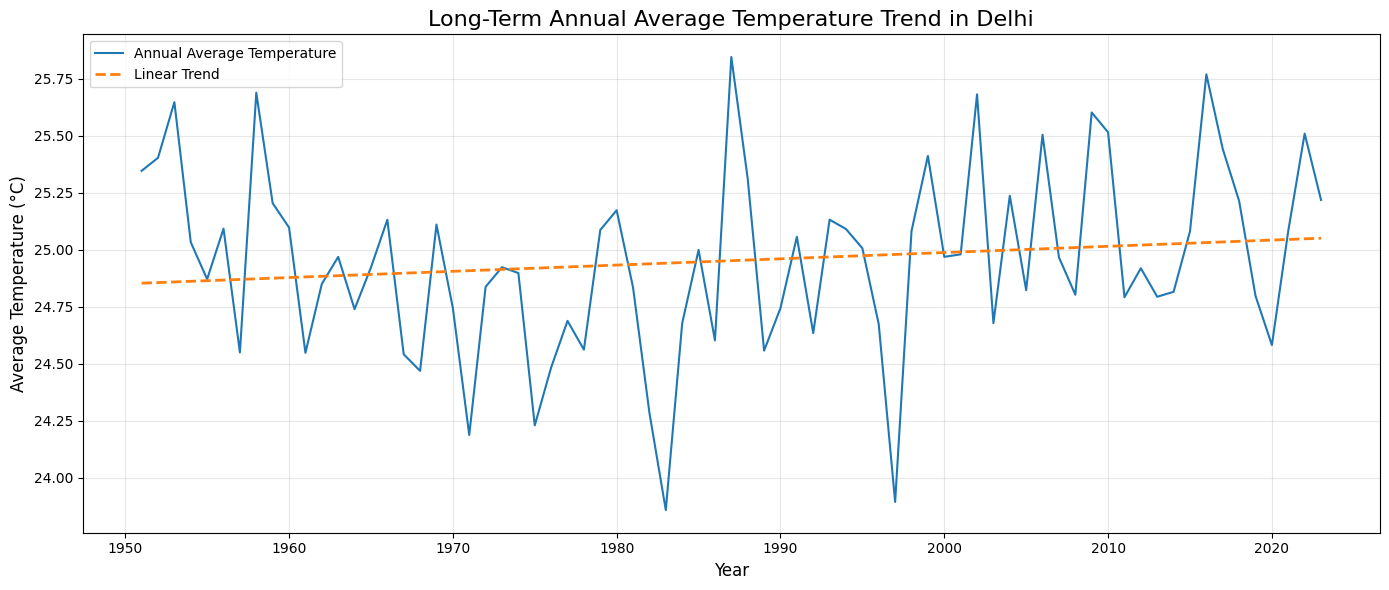

In [19]:
# ============================================
# STEP 6: VISUALIZATION 1
# ANNUAL TEMPERATURE TREND
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    complete_years['Year'],
    complete_years['Average_Temperature'],
    linewidth=1.5,
    label='Annual Average Temperature'
)

# Add linear trend line
z = np.polyfit(
    complete_years['Year'],
    complete_years['Average_Temperature'],
    1
)

trend_line = np.poly1d(z)

plt.plot(
    complete_years['Year'],
    trend_line(complete_years['Year']),
    linestyle='--',
    linewidth=2,
    label='Linear Trend'
)

plt.title(
    'Long-Term Annual Average Temperature Trend in Delhi',
    fontsize=16
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Temperature (°C)', fontsize=12)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
# ============================================
# STEP 7: CALCULATE LONG-TERM TREND
# ============================================

from scipy.stats import linregress

trend_result = linregress(
    complete_years['Year'],
    complete_years['Average_Temperature']
)

slope = trend_result.slope
intercept = trend_result.intercept
r_value = trend_result.rvalue
p_value = trend_result.pvalue
r_squared = r_value ** 2

print("LONG-TERM TEMPERATURE TREND")
print("=" * 40)

print(f"Temperature change per year: {slope:.5f} °C/year")

print(
    f"Estimated temperature change per decade: "
    f"{slope * 10:.3f} °C/decade"
)

print(
    f"Estimated temperature change over the dataset period: "
    f"{slope * (complete_years['Year'].max() - complete_years['Year'].min()):.3f} °C"
)

print(f"R-squared: {r_squared:.4f}")

print(f"P-value: {p_value:.6f}")

LONG-TERM TEMPERATURE TREND
Temperature change per year: 0.00274 °C/year
Estimated temperature change per decade: 0.027 °C/decade
Estimated temperature change over the dataset period: 0.197 °C
R-squared: 0.0203
P-value: 0.229187


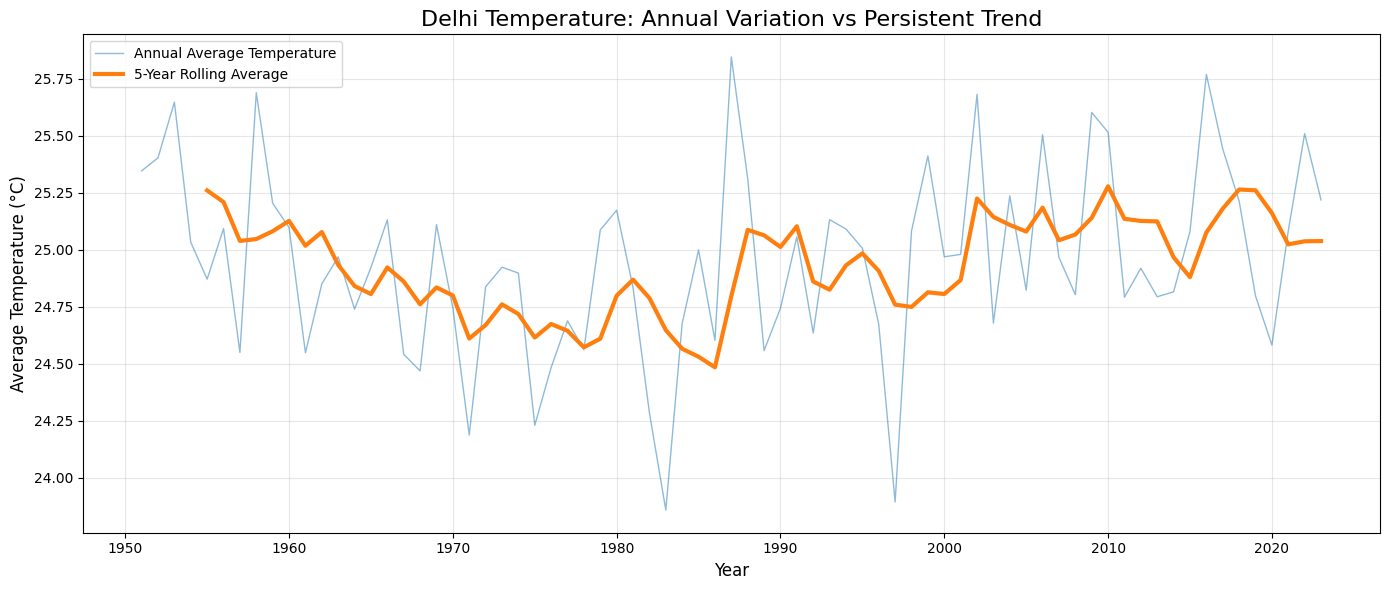

In [22]:
# ============================================
# STEP 9: VISUALIZATION 2
# 5-YEAR ROLLING AVERAGE
# ============================================

rolling_df = complete_years.copy()

# Calculate 5-year rolling average
rolling_df['5_Year_Rolling_Average'] = (
    rolling_df['Average_Temperature']
    .rolling(window=5)
    .mean()
)

plt.figure(figsize=(14, 6))

# Actual annual temperature
plt.plot(
    rolling_df['Year'],
    rolling_df['Average_Temperature'],
    linewidth=1,
    alpha=0.5,
    label='Annual Average Temperature'
)

# 5-year rolling average
plt.plot(
    rolling_df['Year'],
    rolling_df['5_Year_Rolling_Average'],
    linewidth=3,
    label='5-Year Rolling Average'
)

plt.title(
    'Delhi Temperature: Annual Variation vs Persistent Trend',
    fontsize=16
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Temperature (°C)', fontsize=12)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
# ============================================
# STEP 10: SEASONAL TEMPERATURE ANALYSIS
# ============================================

seasonal_df = (
    analysis_df
    .groupby('Season')
    .agg(
        Average_Temperature=('Average_Temperature', 'mean'),
        Average_Max_Temperature=('Temp Max', 'mean'),
        Average_Min_Temperature=('Temp Min', 'mean'),
        Total_Rainfall=('Rain', 'sum'),
        Number_of_Days=('Date', 'count')
    )
    .reset_index()
)

# Put seasons in logical order
season_order = [
    'Winter',
    'Summer',
    'Monsoon',
    'Post-Monsoon'
]

seasonal_df['Season'] = pd.Categorical(
    seasonal_df['Season'],
    categories=season_order,
    ordered=True
)

seasonal_df = seasonal_df.sort_values('Season')

print("SEASONAL CLIMATE SUMMARY")
display(seasonal_df)

SEASONAL CLIMATE SUMMARY


,Season,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature,Total_Rainfall,Number_of_Days
3,Winter,15.389632,22.647143,8.132121,2496.518242,6617
2,Summer,27.844388,35.850749,19.838027,2438.114016,6808
0,Monsoon,30.725477,35.644752,25.806203,42678.101797,8925
1,Post-Monsoon,23.240940,30.841939,15.639942,1985.306811,4453


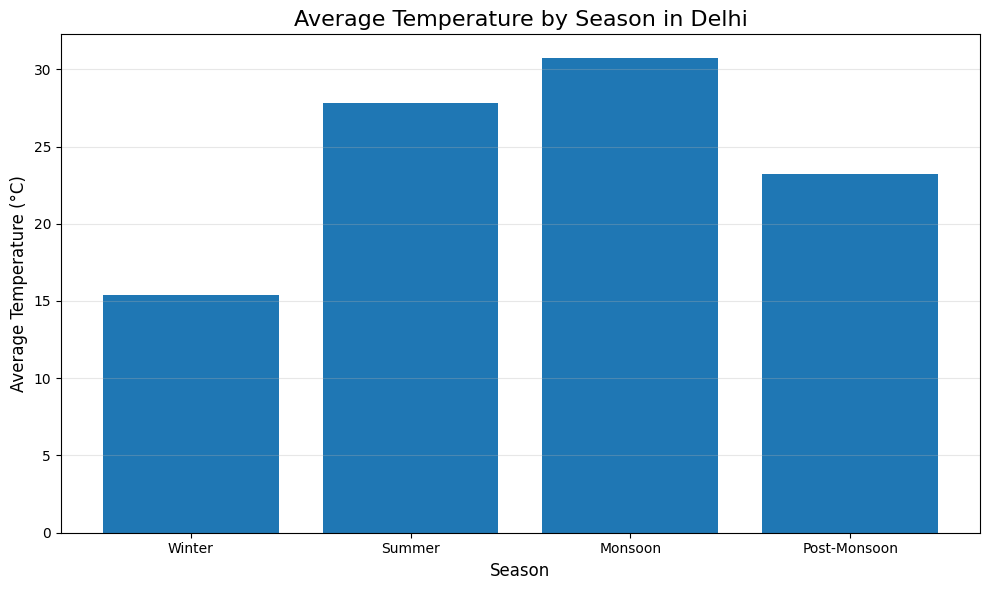

In [24]:
# ============================================
# STEP 11: VISUALIZATION 3
# SEASONAL TEMPERATURE
# ============================================

plt.figure(figsize=(10, 6))

plt.bar(
    seasonal_df['Season'],
    seasonal_df['Average_Temperature']
)

plt.title(
    'Average Temperature by Season in Delhi',
    fontsize=16
)

plt.xlabel('Season', fontsize=12)
plt.ylabel('Average Temperature (°C)', fontsize=12)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [25]:
# ============================================
# STEP 12: MONTHLY TEMPERATURE ANALYSIS
# ============================================

monthly_df = (
    analysis_df
    .groupby('Month')
    .agg(
        Average_Temperature=('Average_Temperature', 'mean'),
        Average_Max_Temperature=('Temp Max', 'mean'),
        Average_Min_Temperature=('Temp Min', 'mean'),
        Total_Rainfall=('Rain', 'sum')
    )
    .reset_index()
)

# Month names
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_df['Month_Name'] = monthly_df['Month'].apply(
    lambda x: month_names[x - 1]
)

print("MONTHLY CLIMATE SUMMARY")
display(monthly_df)

MONTHLY CLIMATE SUMMARY


,Month,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature,Total_Rainfall,Month_Name
0,1,13.740472,20.608128,6.872816,1118.126134,Jan
1,2,17.052817,24.494206,9.611428,959.765237,Feb
2,3,22.438232,30.404027,14.472437,968.288173,Mar
3,4,28.680253,37.011927,20.348579,323.616585,Apr
4,5,32.441642,40.173750,24.709533,1146.209258,May
5,6,33.391164,39.651835,27.130494,3320.098111,Jun
6,7,30.779367,35.190160,26.368575,14462.245863,Jul
7,8,29.695827,33.776976,25.614678,15682.125037,Aug
8,9,29.044949,34.002685,24.087213,9213.632787,Sep
9,10,25.931331,33.140597,18.722066,1729.761838,Oct


In [26]:
# ============================================
# STEP 12: MONTHLY TEMPERATURE ANALYSIS
# ============================================

monthly_df = (
    analysis_df
    .groupby('Month')
    .agg(
        Average_Temperature=('Average_Temperature', 'mean'),
        Average_Max_Temperature=('Temp Max', 'mean'),
        Average_Min_Temperature=('Temp Min', 'mean'),
        Total_Rainfall=('Rain', 'sum')
    )
    .reset_index()
)

# Month names
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_df['Month_Name'] = monthly_df['Month'].apply(
    lambda x: month_names[x - 1]
)

print("MONTHLY CLIMATE SUMMARY")
display(monthly_df)

MONTHLY CLIMATE SUMMARY


,Month,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature,Total_Rainfall,Month_Name
0,1,13.740472,20.608128,6.872816,1118.126134,Jan
1,2,17.052817,24.494206,9.611428,959.765237,Feb
2,3,22.438232,30.404027,14.472437,968.288173,Mar
3,4,28.680253,37.011927,20.348579,323.616585,Apr
4,5,32.441642,40.173750,24.709533,1146.209258,May
5,6,33.391164,39.651835,27.130494,3320.098111,Jun
6,7,30.779367,35.190160,26.368575,14462.245863,Jul
7,8,29.695827,33.776976,25.614678,15682.125037,Aug
8,9,29.044949,34.002685,24.087213,9213.632787,Sep
9,10,25.931331,33.140597,18.722066,1729.761838,Oct


In [27]:
# ============================================
# STEP 13: TEMPERATURE ANOMALY ANALYSIS
# ============================================

# Create a copy
anomaly_df = complete_years.copy()

# --------------------------------------------
# Calculate historical average
# --------------------------------------------

historical_average = (
    anomaly_df['Average_Temperature'].mean()
)

print(
    f"Historical average temperature: "
    f"{historical_average:.2f} °C"
)

# --------------------------------------------
# Calculate anomaly
# --------------------------------------------

anomaly_df['Temperature_Anomaly'] = (
    anomaly_df['Average_Temperature']
    - historical_average
)

# --------------------------------------------
# Standard deviation
# --------------------------------------------

std_temperature = (
    anomaly_df['Average_Temperature'].std()
)

print(
    f"Historical standard deviation: "
    f"{std_temperature:.2f} °C"
)

# --------------------------------------------
# Classify unusual years
# --------------------------------------------

anomaly_df['Anomaly_Type'] = 'Normal'

anomaly_df.loc[
    anomaly_df['Temperature_Anomaly'] >= std_temperature,
    'Anomaly_Type'
] = 'Unusually Hot'

anomaly_df.loc[
    anomaly_df['Temperature_Anomaly'] <= -std_temperature,
    'Anomaly_Type'
] = 'Unusually Cold'

# --------------------------------------------
# Display extreme years
# --------------------------------------------

print("\nHottest anomalies:")
display(
    anomaly_df
    .nlargest(10, 'Temperature_Anomaly')
    [
        [
            'Year',
            'Average_Temperature',
            'Temperature_Anomaly',
            'Anomaly_Type'
        ]
    ]
)

print("\nColdest anomalies:")
display(
    anomaly_df
    .nsmallest(10, 'Temperature_Anomaly')
    [
        [
            'Year',
            'Average_Temperature',
            'Temperature_Anomaly',
            'Anomaly_Type'
        ]
    ]
)

# --------------------------------------------
# Count anomaly categories
# --------------------------------------------

print("\nAnomaly classification:")
display(
    anomaly_df['Anomaly_Type'].value_counts()
)

Historical average temperature: 24.95 °C
Historical standard deviation: 0.41 °C

Hottest anomalies:


,Year,Average_Temperature,Temperature_Anomaly,Anomaly_Type
36,1987,25.845521,0.893913,Unusually Hot
65,2016,25.769279,0.817672,Unusually Hot
7,1958,25.688740,0.737133,Unusually Hot
51,2002,25.681493,0.729886,Unusually Hot
2,1953,25.647356,0.695749,Unusually Hot
58,2009,25.602178,0.650571,Unusually Hot
59,2010,25.515137,0.563530,Unusually Hot
71,2022,25.509178,0.557571,Unusually Hot
55,2006,25.504206,0.552598,Unusually Hot
66,2017,25.441953,0.490346,Unusually Hot



Coldest anomalies:


,Year,Average_Temperature,Temperature_Anomaly,Anomaly_Type
32,1983,23.857247,-1.094361,Unusually Cold
46,1997,23.892945,-1.058662,Unusually Cold
20,1971,24.186685,-0.764922,Unusually Cold
24,1975,24.228877,-0.722730,Unusually Cold
31,1982,24.283918,-0.667689,Unusually Cold
17,1968,24.468087,-0.483520,Unusually Cold
25,1976,24.482882,-0.468725,Unusually Cold
16,1967,24.540781,-0.410826,Unusually Cold
10,1961,24.547247,-0.404361,Normal
6,1957,24.548849,-0.402758,Normal



Anomaly classification:


,count
Anomaly_Type,
Normal,53
Unusually Hot,12
Unusually Cold,8


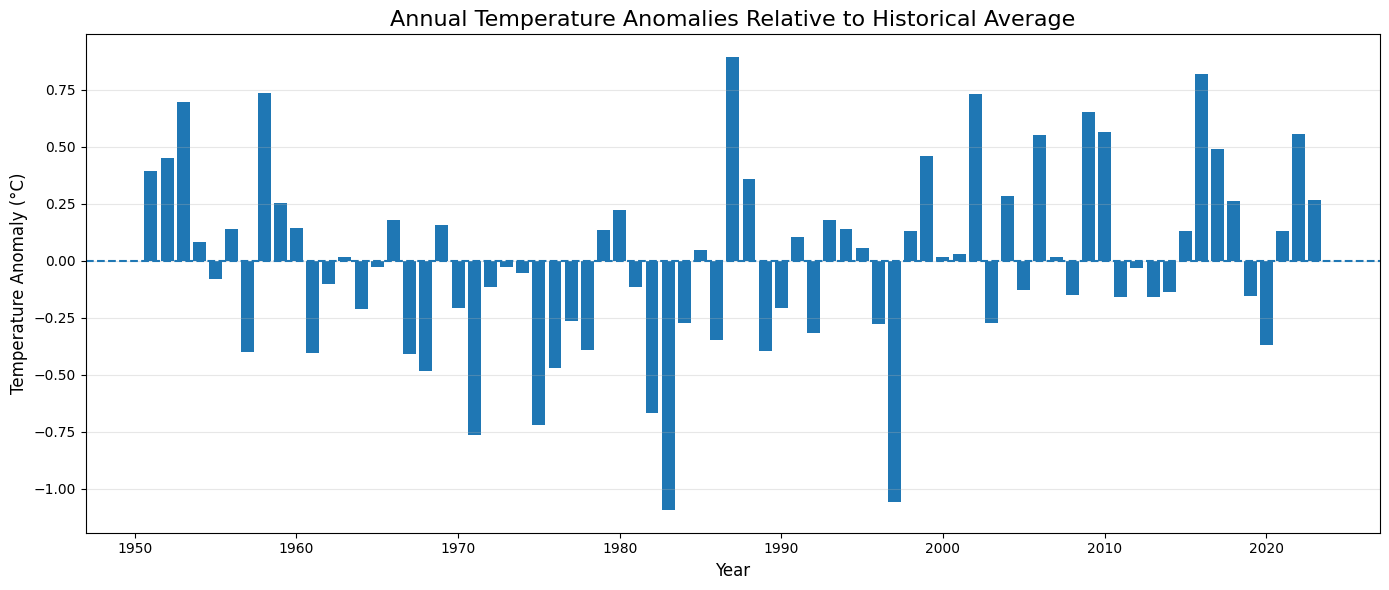

In [28]:
# ============================================
# STEP 14: VISUALIZATION 4
# TEMPERATURE ANOMALIES
# ============================================

plt.figure(figsize=(14, 6))

plt.bar(
    anomaly_df['Year'],
    anomaly_df['Temperature_Anomaly'],
    width=0.8
)

plt.axhline(
    y=0,
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Annual Temperature Anomalies Relative to Historical Average',
    fontsize=16
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Temperature Anomaly (°C)', fontsize=12)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

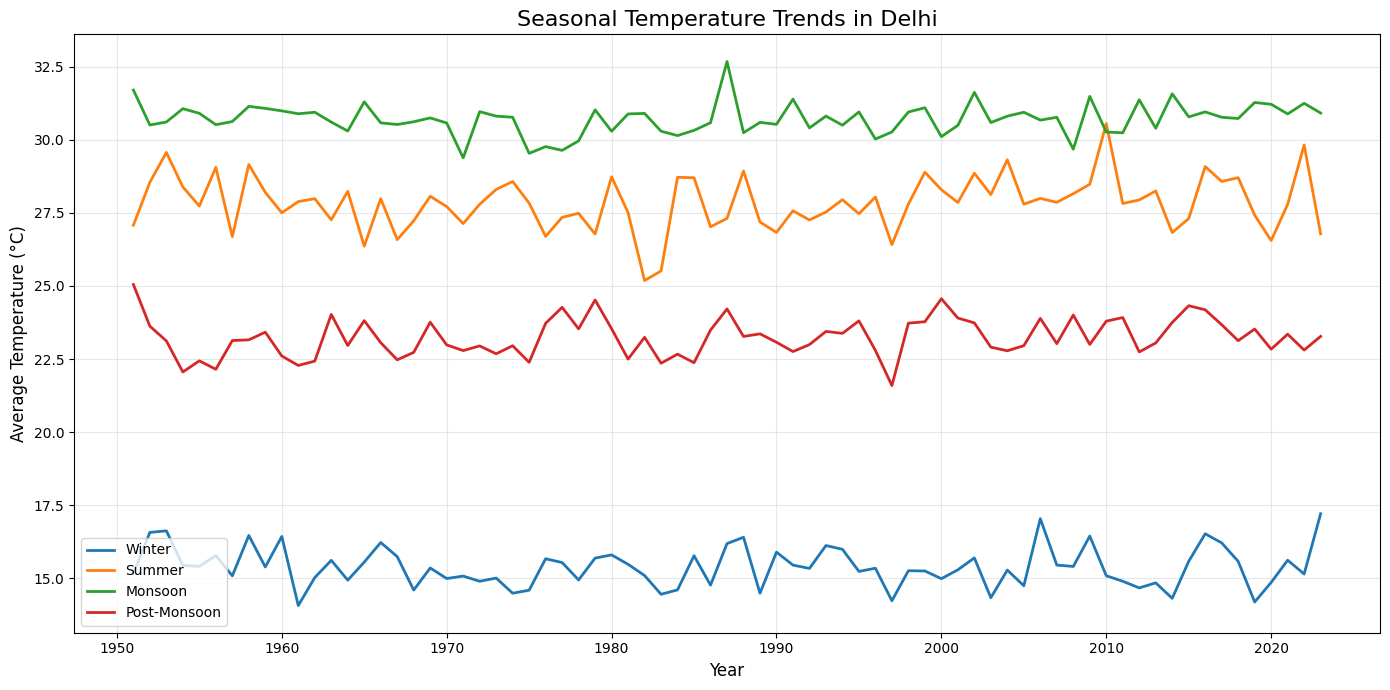

In [29]:
# ============================================
# STEP 15: SEASONAL TREND OVER TIME
# ============================================

seasonal_yearly = (
    analysis_df
    .groupby(['Year', 'Season'])
    ['Average_Temperature']
    .mean()
    .reset_index()
)

# Remove incomplete 2024
seasonal_yearly = seasonal_yearly[
    seasonal_yearly['Year'].isin(
        complete_years['Year']
    )
]

# --------------------------------------------
# Plot seasonal trends
# --------------------------------------------

plt.figure(figsize=(14, 7))

for season in season_order:

    season_data = seasonal_yearly[
        seasonal_yearly['Season'] == season
    ]

    plt.plot(
        season_data['Year'],
        season_data['Average_Temperature'],
        label=season,
        linewidth=2
    )

plt.title(
    'Seasonal Temperature Trends in Delhi',
    fontsize=16
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Temperature (°C)', fontsize=12)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [30]:
# ============================================
# STEP 16: PREPARE DATA FOR LINEAR REGRESSION
# ============================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use complete years only
model_df = complete_years[
    ['Year', 'Average_Temperature']
].copy()

# Sort chronologically
model_df = model_df.sort_values('Year').reset_index(drop=True)

print("Model dataset:")
display(model_df.head())

print("\nLast records:")
display(model_df.tail())

print("\nNumber of years:", len(model_df))

# --------------------------------------------
# Define X and y
# --------------------------------------------

X = model_df[['Year']]

y = model_df['Average_Temperature']

# --------------------------------------------
# Chronological 80/20 split
# --------------------------------------------

split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("\nTraining years:")
print(
    X_train['Year'].min(),
    "to",
    X_train['Year'].max()
)

print("\nTesting years:")
print(
    X_test['Year'].min(),
    "to",
    X_test['Year'].max()
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Model dataset:


,Year,Average_Temperature
0,1951,25.345932
1,1952,25.403169
2,1953,25.647356
3,1954,25.032342
4,1955,24.870616



Last records:


,Year,Average_Temperature
68,2019,24.797250
69,2020,24.581299
70,2021,25.082466
71,2022,25.509178
72,2023,25.218242



Number of years: 73

Training years:
1951 to 2008

Testing years:
2009 to 2023

Training samples: 58
Testing samples: 15


In [31]:
# ============================================
# STEP 17: TRAIN LINEAR REGRESSION MODEL
# ============================================

model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# --------------------------------------------
# Model parameters
# --------------------------------------------

slope = model.coef_[0]
intercept = model.intercept_

print("LINEAR REGRESSION MODEL")
print("=" * 40)

print(f"Slope: {slope:.6f} °C/year")
print(f"Intercept: {intercept:.4f}")

print(
    f"\nEstimated temperature change per decade: "
    f"{slope * 10:.4f} °C/decade"
)

LINEAR REGRESSION MODEL
Slope: -0.000854 °C/year
Intercept: 26.5930

Estimated temperature change per decade: -0.0085 °C/decade


In [32]:
# ============================================
# STEP 19: MODEL EVALUATION
# ============================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("=" * 40)

print(f"MAE  : {mae:.4f} °C")
print(f"RMSE : {rmse:.4f} °C")
print(f"R²   : {r2:.4f}")

NameError: name 'y_pred' is not defined

In [33]:
# ============================================
# STEP 18: GENERATE PREDICTIONS
# ============================================

y_pred = model.predict(X_test)

prediction_df = pd.DataFrame({
    'Year': X_test['Year'].values,
    'Actual_Temperature': y_test.values,
    'Predicted_Temperature': y_pred
})

prediction_df['Error'] = (
    prediction_df['Actual_Temperature']
    - prediction_df['Predicted_Temperature']
)

print("Actual vs Predicted:")
display(prediction_df)

Actual vs Predicted:


,Year,Actual_Temperature,Predicted_Temperature,Error
0,2009,25.602178,24.877195,0.724983
1,2010,25.515137,24.876341,0.638796
2,2011,24.791274,24.875487,-0.084213
3,2012,24.918443,24.874633,0.043810
4,2013,24.793315,24.873779,-0.080464
5,2014,24.815014,24.872925,-0.057911
6,2015,25.080232,24.872071,0.208161
7,2016,25.769279,24.871217,0.898062
8,2017,25.441953,24.870363,0.571590
9,2018,25.213432,24.869509,0.343923


In [34]:
# ============================================
# STEP 19: MODEL EVALUATION
# ============================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("=" * 40)

print(f"MAE  : {mae:.4f} °C")
print(f"RMSE : {rmse:.4f} °C")
print(f"R²   : {r2:.4f}")

MODEL EVALUATION RESULTS
MAE  : 0.3481 °C
RMSE : 0.4411 °C
R²   : -0.6019


In [35]:
# ============================================
# STEP 21: STATISTICAL SIGNIFICANCE TEST
# ============================================

from scipy.stats import linregress

trend = linregress(
    model_df['Year'],
    model_df['Average_Temperature']
)

print("STATISTICAL TREND TEST")
print("=" * 40)

print(f"Slope: {trend.slope:.6f} °C/year")
print(f"Change per decade: {trend.slope * 10:.4f} °C/decade")
print(f"R-value: {trend.rvalue:.4f}")
print(f"R²: {trend.rvalue ** 2:.4f}")
print(f"P-value: {trend.pvalue:.6f}")
print(f"Standard error: {trend.stderr:.6f}")

STATISTICAL TREND TEST
Slope: 0.002742 °C/year
Change per decade: 0.0274 °C/decade
R-value: 0.1425
R²: 0.0203
P-value: 0.229187
Standard error: 0.002260


In [36]:
print(model_df.shape)
print(model_df['Year'].min(), model_df['Year'].max())
print(model.coef_[0])
print(trend.slope)

(73, 2)
1951 2023
-0.0008540696174699135
0.0027417088169968207


In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import linregress
import numpy as np

# Prepare data
model_df = complete_years[['Year', 'Average_Temperature']].copy()
model_df = model_df.sort_values('Year').reset_index(drop=True)

X = model_df[['Year']]
y = model_df['Average_Temperature']

# Chronological 80/20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Statistical trend using ALL complete years
trend = linregress(
    model_df['Year'],
    model_df['Average_Temperature']
)

print("FINAL LINEAR REGRESSION RESULTS")
print("=" * 50)
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Model slope: {model.coef_[0]:.6f} °C/year")
print(f"Model intercept: {model.intercept_:.4f}")

print("\nMODEL EVALUATION")
print("=" * 50)
print(f"MAE:  {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"R²:   {r2:.4f}")

print("\nSTATISTICAL TREND TEST")
print("=" * 50)
print(f"Slope: {trend.slope:.6f} °C/year")
print(f"Change per decade: {trend.slope * 10:.4f} °C/decade")
print(f"R-value: {trend.rvalue:.4f}")
print(f"R²: {trend.rvalue ** 2:.4f}")
print(f"P-value: {trend.pvalue:.6f}")
print(f"Standard error: {trend.stderr:.6f}")

FINAL LINEAR REGRESSION RESULTS
Training samples: 58
Testing samples: 15
Model slope: -0.000854 °C/year
Model intercept: 26.5930

MODEL EVALUATION
MAE:  0.3481 °C
RMSE: 0.4411 °C
R²:   -0.6019

STATISTICAL TREND TEST
Slope: 0.002742 °C/year
Change per decade: 0.0274 °C/decade
R-value: 0.1425
R²: 0.0203
P-value: 0.229187
Standard error: 0.002260


In [21]:
# ============================================
# STEP 8: HOTTEST AND COLDEST YEARS
# ============================================

# Hottest years
hottest_years = (
    complete_years
    .nlargest(10, 'Average_Temperature')
    [
        [
            'Year',
            'Average_Temperature',
            'Average_Max_Temperature',
            'Average_Min_Temperature'
        ]
    ]
)

# Coldest years
coldest_years = (
    complete_years
    .nsmallest(10, 'Average_Temperature')
    [
        [
            'Year',
            'Average_Temperature',
            'Average_Max_Temperature',
            'Average_Min_Temperature'
        ]
    ]
)

print("TOP 10 HOTTEST YEARS")
display(hottest_years)

print("\nTOP 10 COLDEST YEARS")
display(coldest_years)

TOP 10 HOTTEST YEARS


,Year,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature
36,1987,25.845521,33.009945,18.681096
65,2016,25.769279,32.338567,19.199990
7,1958,25.688740,32.391315,18.986164
51,2002,25.681493,32.269973,19.093014
2,1953,25.647356,32.458849,18.835863
58,2009,25.602178,32.541589,18.662767
59,2010,25.515137,32.130055,18.900219
71,2022,25.509178,32.020548,18.997808
55,2006,25.504206,32.107507,18.900904
66,2017,25.441953,32.140318,18.743588



TOP 10 COLDEST YEARS


,Year,Average_Temperature,Average_Max_Temperature,Average_Min_Temperature
32,1983,23.857247,30.587644,17.126849
46,1997,23.892945,29.962685,17.823205
20,1971,24.186685,30.931479,17.441890
24,1975,24.228877,30.850137,17.607616
31,1982,24.283918,30.825370,17.742466
17,1968,24.468087,31.526339,17.409836
25,1976,24.482882,31.136120,17.829645
16,1967,24.540781,31.471096,17.610466
10,1961,24.547247,31.003041,18.091452
6,1957,24.548849,31.137123,17.960575


In [39]:
print("===== ANNUAL TEMPERATURE SUMMARY =====")
print(f"Overall average temperature: {complete_years['Average_Temperature'].mean():.2f} °C")
print(f"Minimum annual average temperature: {complete_years['Average_Temperature'].min():.2f} °C")
print(f"Maximum annual average temperature: {complete_years['Average_Temperature'].max():.2f} °C")

coldest_year = complete_years.loc[
    complete_years['Average_Temperature'].idxmin()
]

hottest_year = complete_years.loc[
    complete_years['Average_Temperature'].idxmax()
]

print(f"Coldest year: {int(coldest_year['Year'])} "
      f"({coldest_year['Average_Temperature']:.2f} °C)")

print(f"Hottest year: {int(hottest_year['Year'])} "
      f"({hottest_year['Average_Temperature']:.2f} °C)")


print("\n===== SEASONAL SUMMARY =====")
print(
    seasonal_df[
        ['Season', 'Average_Temperature', 'Average_Max_Temperature',
         'Average_Min_Temperature', 'Total_Rainfall']
    ].to_string(index=False)
)


print("\n===== HOT/COLD ANOMALIES =====")
print(
    anomaly_df[
        ['Year', 'Average_Temperature',
         'Temperature_Anomaly', 'Anomaly_Type']
    ]
    .sort_values('Temperature_Anomaly', ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\n===== TREND TEST =====")
print(f"Slope: {trend.slope:.6f} °C/year")
print(f"Decadal change: {trend.slope * 10:.4f} °C/decade")
print(f"P-value: {trend.pvalue:.6f}")
print(f"R²: {trend.rvalue ** 2:.4f}")

print("\n===== MODEL PERFORMANCE =====")
print(f"MAE: {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"Test R²: {r2:.4f}")

===== ANNUAL TEMPERATURE SUMMARY =====
Overall average temperature: 24.95 °C
Minimum annual average temperature: 23.86 °C
Maximum annual average temperature: 25.85 °C
Coldest year: 1983 (23.86 °C)
Hottest year: 1987 (25.85 °C)

===== SEASONAL SUMMARY =====
      Season  Average_Temperature  Average_Max_Temperature  Average_Min_Temperature  Total_Rainfall
      Winter            15.389632                22.647143                 8.132121     2496.518242
      Summer            27.844388                35.850749                19.838027     2438.114016
     Monsoon            30.725477                35.644752                25.806203    42678.101797
Post-Monsoon            23.240940                30.841939                15.639942     1985.306811

===== HOT/COLD ANOMALIES =====
 Year  Average_Temperature  Temperature_Anomaly  Anomaly_Type
 1987            25.845521             0.893913 Unusually Hot
 2016            25.769279             0.817672 Unusually Hot
 1958            25.68874

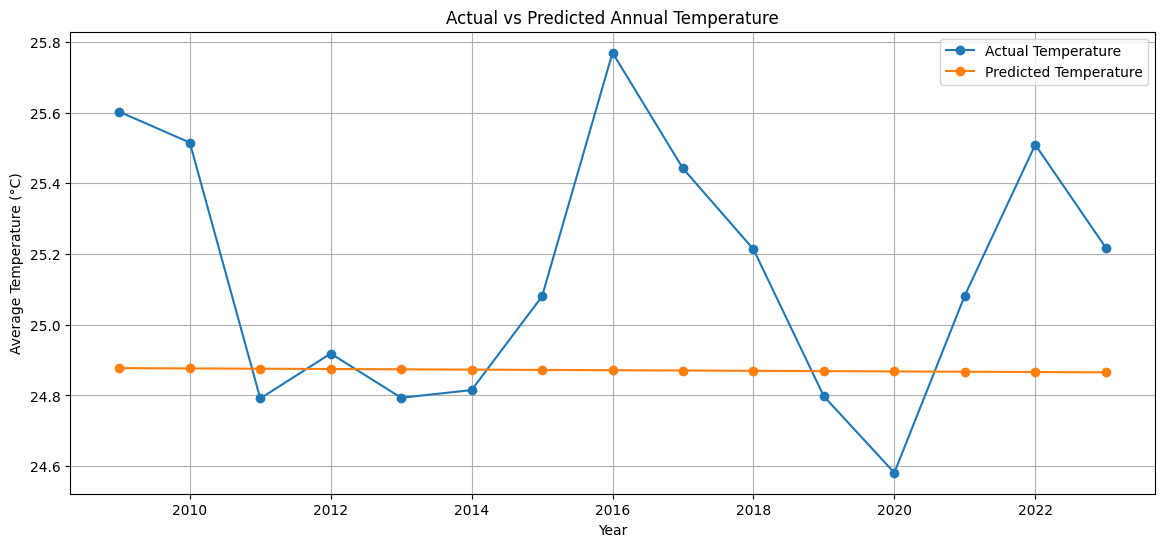

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    X_test['Year'],
    y_test,
    marker='o',
    label='Actual Temperature'
)

plt.plot(
    X_test['Year'],
    y_pred,
    marker='o',
    label='Predicted Temperature'
)

plt.xlabel('Year')
plt.ylabel('Average Temperature (°C)')
plt.title('Actual vs Predicted Annual Temperature')
plt.legend()
plt.grid(True)
plt.show()